# **EDA for an air quality data**

**note :** this is a self check to asses my skils by doing exploretary data analysis to the data after the IBM data analytics profficional cirtificate 

This dataset contains air quality measurements collected from urban locations in Saudi Arabia, focusing on pollutants and meteorological parameters. It is designed for machine learning-based source classification (e.g., Traffic, Industrial, Biomass) and pollutant level forecasting. The dataset is inspired by the UCI Air Quality dataset but extended with a Source label for supervised classification tasks.

The dataset includes timestamped readings of key gases like CO, NMHC, NOx, NO₂, O₃, and supporting meteorological factors such as temperature (T), relative humidity (RH), and absolute humidity (AH).

**source :** kaggle path "srisyra02/air-quality-dataset"


<h4>let us start by loding the desired librarys<h4>

In [4]:
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn
!pip install seaborn
!pip install pathlib


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


then we will Import the libraries we need to use in this lab

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
print("importing wass sucssesfull")

importing wass sucssesfull


then we shall import the file that i have previosly downloaded

In [13]:
DATA_PATH = Path("../../data/raw/air_quality_dataset.csv")
print("done")

done


In [14]:
#I dont always do this , but it's better to set your output files in the bigging of the document , so .....

OUTPUT_PATH = Path("../../outputs/figures")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


next we will read the data

In [15]:
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")

Dataset loaded successfully!


then check the data itself 

In [16]:
# Dataset dimensions
print("Shape:", df.shape)
# First records
display(df.head())
# Last records
display(df.tail())
# Random sample
display(df.sample(5, random_state=42))
# Column names
print(df.columns.tolist())
# Data types
print(df.dtypes)
# Dataset information
df.info()
# Statistical summary
display(df.describe().T)

Shape: (500, 10)


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
495,51.380025,57.573550,31.124630,19.276010,11.167098,104.071502,1.844483,397.418878,1.923525,34.323410
496,46.816837,75.372133,22.174014,18.535162,12.169426,74.802208,1.364096,392.316075,2.157281,26.321361
497,33.909351,88.097250,27.630317,15.653370,7.997326,128.105470,2.319453,378.653347,1.809489,28.964494
498,43.721651,40.847991,27.253977,19.365916,7.218154,106.053329,1.599748,389.878566,1.858964,29.976442
499,43.135587,34.287210,4.290139,5.122962,7.415822,93.332250,1.633200,388.029985,2.059903,26.649351


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
361,26.548982,67.391718,25.540563,15.565702,7.273767,49.813578,1.344661,386.943809,2.126732,25.905401
73,35.961208,53.065871,89.137594,36.908279,5.444268,70.425028,2.627878,411.053927,1.762626,29.120538
374,34.236104,57.787207,92.240780,33.988519,5.530397,67.073694,2.088690,399.001268,1.680025,32.196658
155,84.233115,134.931202,138.620102,52.919981,13.431673,132.622343,2.333705,493.927666,2.892274,32.245444
104,57.061711,65.457159,33.406000,22.175908,9.128806,108.888766,0.826086,380.662778,2.209384,29.709851


['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']
PM2.5          float64
PM10           float64
NOx            float64
NO2            float64
SO2            float64
VOCs           float64
CO             float64
CO2            float64
CH4            float64
Temperature    float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PM2.5        500 non-null    float64
 1   PM10         500 non-null    float64
 2   NOx          500 non-null    float64
 3   NO2          500 non-null    float64
 4   SO2          500 non-null    float64
 5   VOCs         500 non-null    float64
 6   CO           500 non-null    float64
 7   CO2          500 non-null    float64
 8   CH4          500 non-null    float64
 9   Temperature  500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB


,count,mean,std,min,25%,50%,75%,max
PM2.5,500.0,54.671620,22.799473,10.757597,36.372940,48.038599,73.820566,127.616632
PM10,500.0,84.703251,30.567912,12.932337,61.118607,78.135558,110.270086,171.594187
NOx,500.0,91.814080,54.808414,-0.076323,35.457263,95.452284,134.709240,225.886935
NO2,500.0,42.410820,26.343669,-1.942140,17.448632,39.211583,63.817763,115.916428
SO2,500.0,11.504816,7.306978,-1.095555,5.976492,8.681222,17.116673,31.941860
VOCs,500.0,112.193098,39.471686,27.555617,81.516729,104.819124,140.588100,231.926017
CO,500.0,2.177705,0.824762,0.366992,1.536915,2.045519,2.726020,4.798935
CO2,500.0,439.288087,51.220578,366.063158,397.399610,420.934319,490.968315,558.924256
CH4,500.0,2.130439,0.391396,1.388407,1.837395,2.066709,2.386267,3.352266
Temperature,500.0,30.448413,2.957290,19.581349,28.481974,30.432756,32.614954,39.778713


know that we have a better understanding of the data , let's check the quality of it 

In [17]:
# Missing values
print("Missing values:")
print(df.isnull().sum())
# Missing value percentage
print("\nMissing percentages:")
print(df.isnull().mean() * 100)
# Duplicate records
print("\nDuplicates:", df.duplicated().sum())
# Unique values
print("\nUnique values:")
print(df.nunique())
# Negative values
print("\nNegative values:")
print((df.select_dtypes(include=np.number) < 0).sum())

Missing values:
PM2.5          0
PM10           0
NOx            0
NO2            0
SO2            0
VOCs           0
CO             0
CO2            0
CH4            0
Temperature    0
dtype: int64

Missing percentages:
PM2.5          0.0
PM10           0.0
NOx            0.0
NO2            0.0
SO2            0.0
VOCs           0.0
CO             0.0
CO2            0.0
CH4            0.0
Temperature    0.0
dtype: float64

Duplicates: 0

Unique values:
PM2.5          500
PM10           500
NOx            500
NO2            500
SO2            500
VOCs           500
CO             500
CO2            500
CH4            500
Temperature    500
dtype: int64

Negative values:
PM2.5          0
PM10           0
NOx            1
NO2            1
SO2            2
VOCs           0
CO             0
CO2            0
CH4            0
Temperature    0
dtype: int64


next , we will do **Univariate analysis** to Explore individual variables and their distributions.

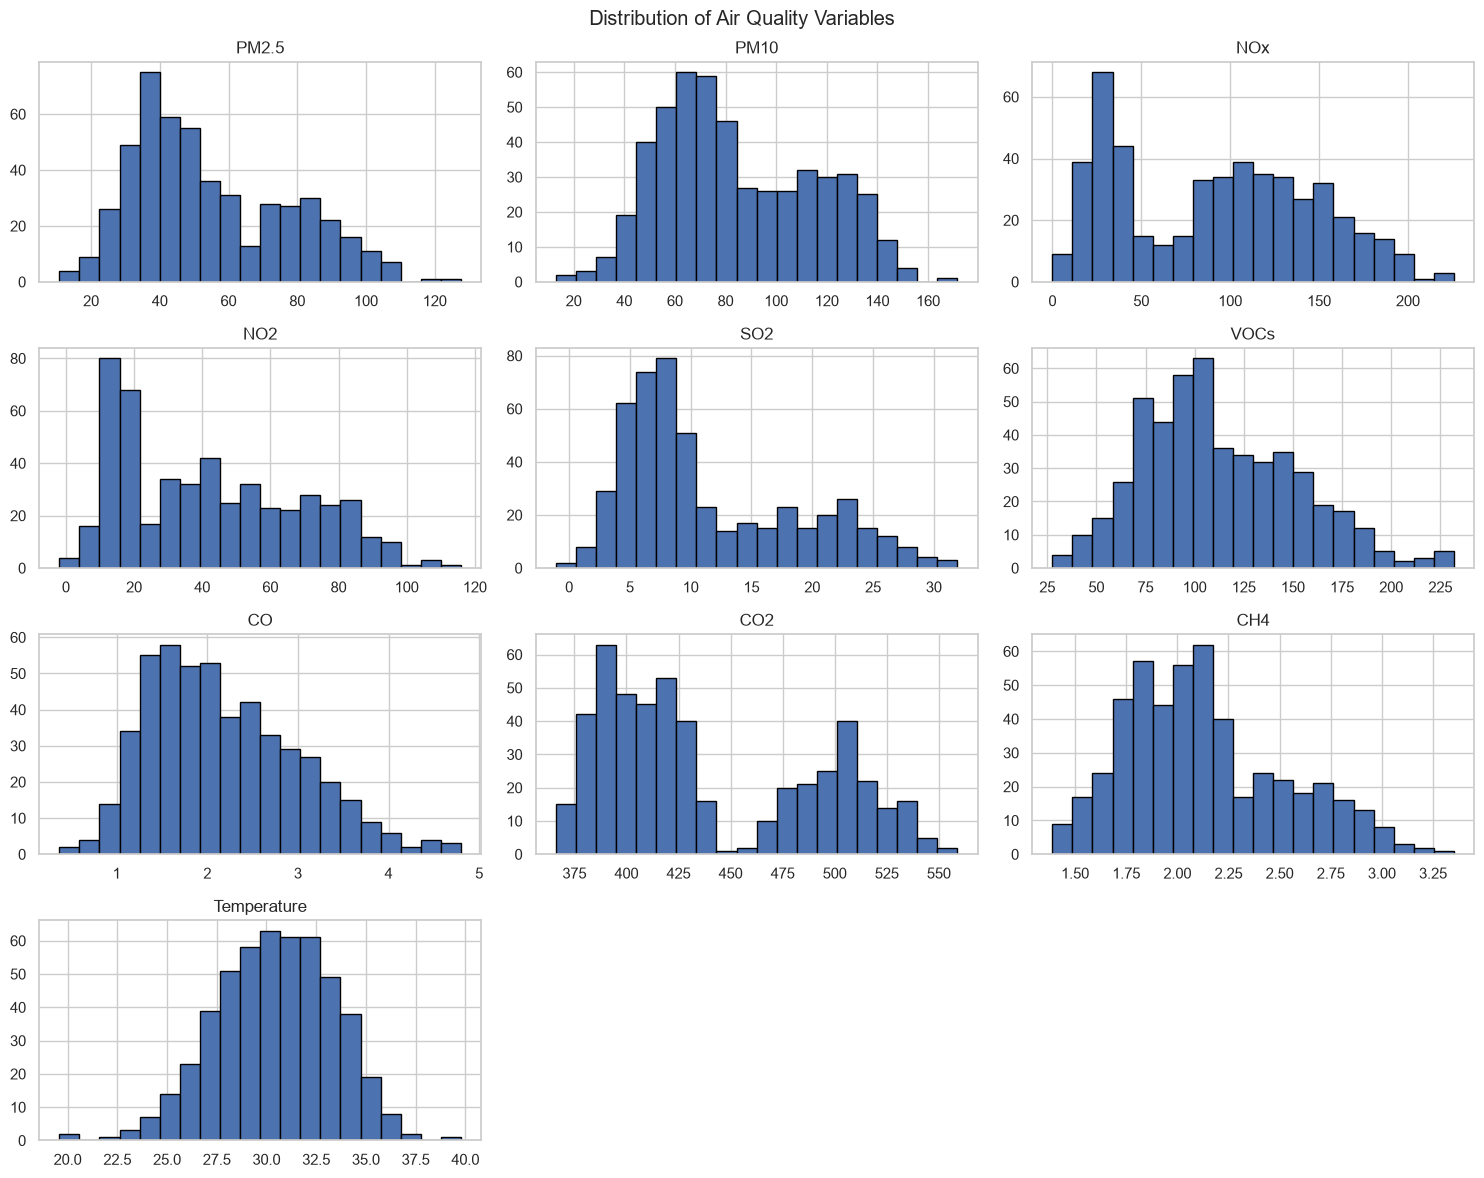

In [18]:
# Histograms
df.hist(
    bins=20,
    figsize=(15, 12),
    edgecolor="black"
)

plt.suptitle("Distribution of Air Quality Variables")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "distributions.png", dpi=300)
plt.show()

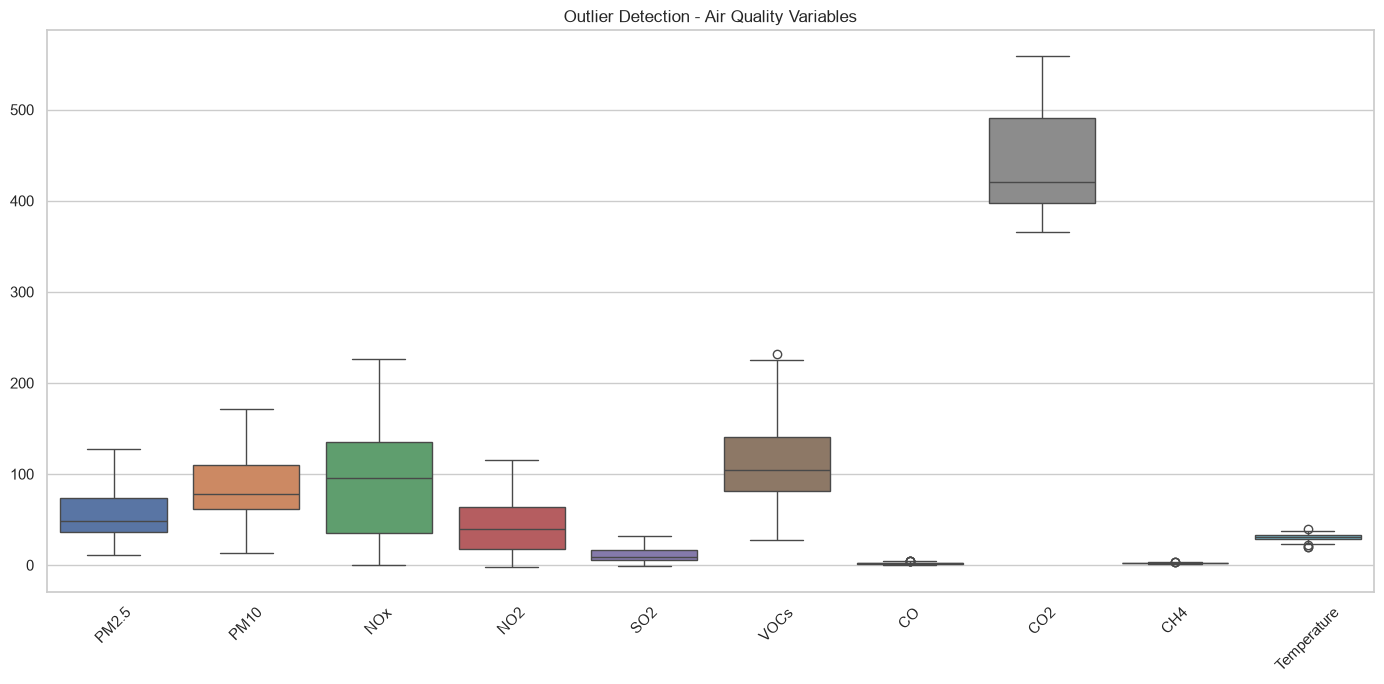

In [19]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df)

plt.title("Outlier Detection - Air Quality Variables")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(OUTPUT_PATH / "boxplots.png", dpi=300)
plt.show()


next , we should do the **Correlation analysis** This is particularly useful for understanding relationships between pollutants.

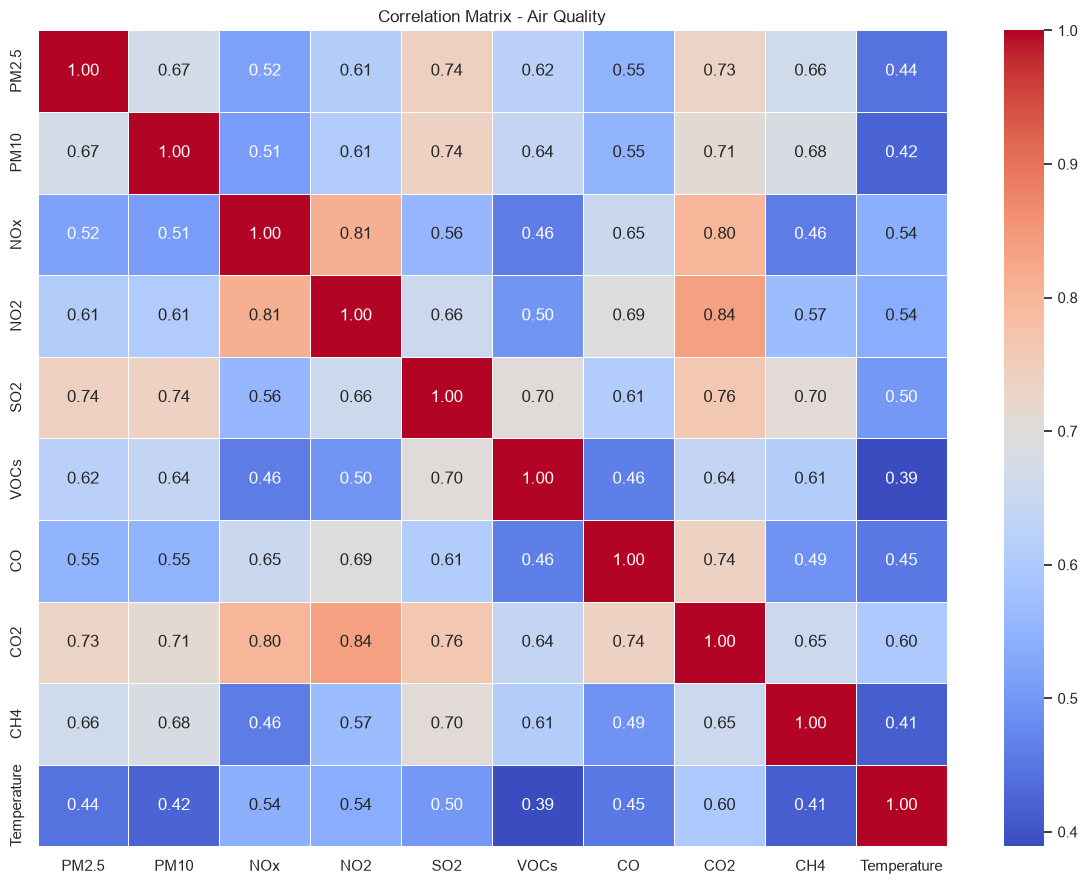

In [20]:
correlation = df.corr()
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix - Air Quality")
plt.tight_layout()

plt.savefig(OUTPUT_PATH / "correlation_matrix.png", dpi=300)
plt.show()

after that we have the **Bivariate analysis** to Investigate relationships between selected variables.

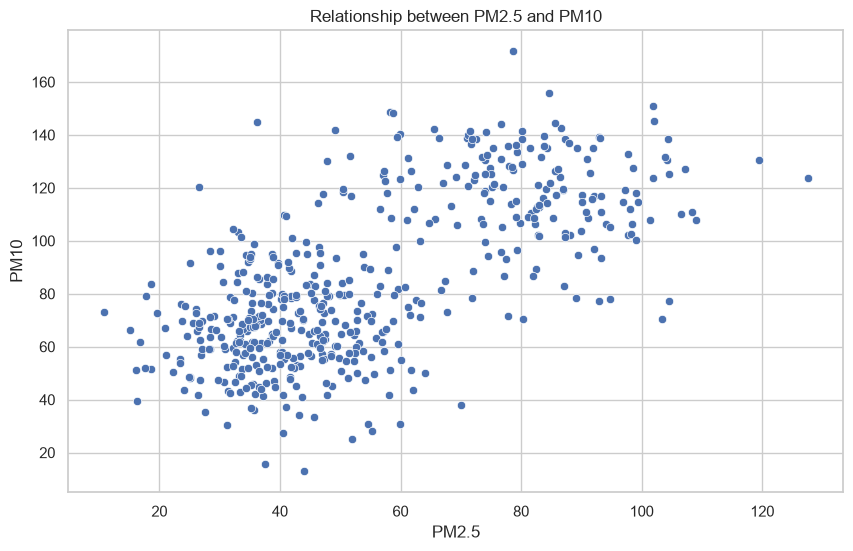

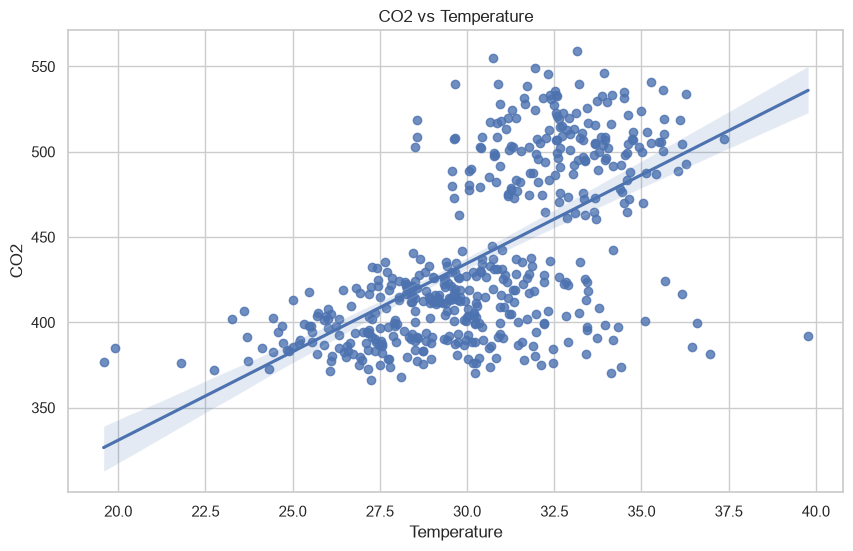

In [21]:
# PM2.5 vs PM10
sns.scatterplot(
    data=df,
    x="PM2.5",
    y="PM10"
)

plt.title("Relationship between PM2.5 and PM10")
plt.savefig(OUTPUT_PATH / "pm25_vs_pm10.png", dpi=300)
plt.show()


# CO2 vs Temperature
sns.regplot(
    data=df,
    x="Temperature",
    y="CO2"
)

plt.title("CO2 vs Temperature")
plt.savefig(OUTPUT_PATH / "co2_vs_temperature.png", dpi=300)
plt.show()

Pairwise relationships

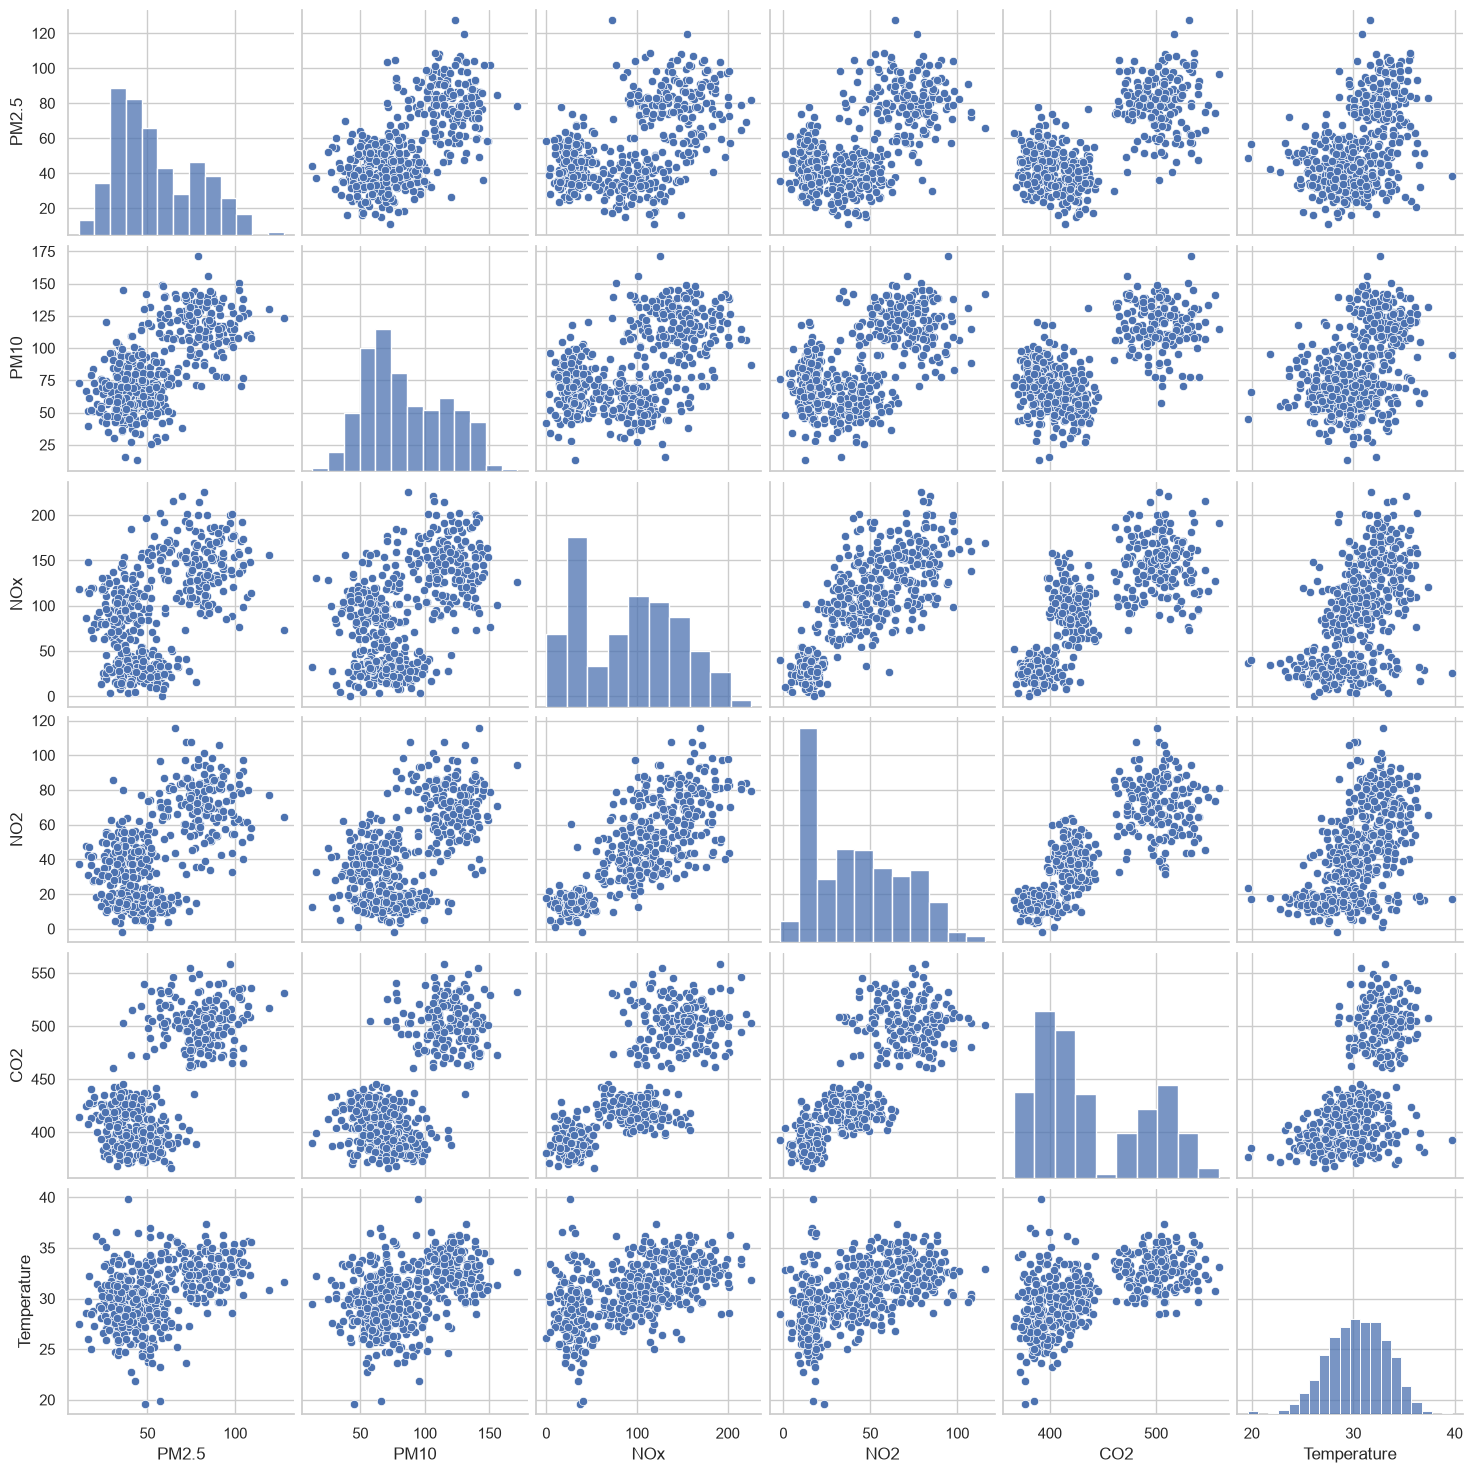

In [23]:
sns.pairplot(
    df[["PM2.5", "PM10", "NOx", "NO2", "CO2", "Temperature"]],
    diag_kind="hist"
)

plt.savefig(
    OUTPUT_PATH / "pairplot.png",
    dpi=300
)

plt.show()

Identify strongest correlations

In [24]:
correlation = df.corr()

# Extract upper triangle to avoid duplicate pairs
upper_triangle = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

strongest_correlations = (
    upper_triangle.stack()
    .sort_values(ascending=False)
)

print("Strongest correlations:")
display(strongest_correlations.head(10))

Strongest correlations:


NO2    CO2    0.836998
NOx    NO2    0.812817
       CO2    0.800643
SO2    CO2    0.761631
PM2.5  SO2    0.740100
CO     CO2    0.738116
PM10   SO2    0.737051
PM2.5  CO2    0.731254
PM10   CO2    0.709261
SO2    CH4    0.704122
dtype: float64

Export analysis results

In [25]:
# Export descriptive statistics
df.describe().T.to_csv(
    OUTPUT_PATH / "descriptive_statistics.csv"
)

# Export correlation matrix
df.corr().to_csv(
    OUTPUT_PATH / "correlation_matrix.csv"
)

print("Analysis outputs exported successfully!")

Analysis outputs exported successfully!
